# Block 5. Spatial patterns

Owner: Felipe. Plan: `docs/eda-plan.md`, block 5. Task: `docs/open-tasks.md`, task 1. Findings: `docs/findings/05-spatial.md`.
Input: `processed/harmonized/cells_daily.parquet` (harmonized hotspots per 0.25° cell and `burn_date`) and, for 5.3, `processed/quality/static_mask_cells.parquet`.
Output: `NASA_Data_Sources/processed/spatial/cell_regimes.parquet` (git-ignored).

Rules (from `docs/eda-runbook.md`):

- Counts are the **sum of `hotspots_harmonized`** (VIIRS-equivalent hotspots). Never count rows: a cell on a region border has one row per region.
- Days, months and years come from `burn_date`. One sensor per period: MODIS (scaled to VIIRS) before 2012-02-01, Suomi-NPP until 2026-10-31, NOAA-20 after.
- A cell is identified by its south-west corner: `cell_lat = floor(latitude * 4) / 4`, same for longitude.
- A 0.25° cell shrinks with latitude: `area_km2 = (0.25 * 111.32) ** 2 * cos(radians(cell_lat + 0.125))`. Densities are per km².
- Hotspots are detections, not fires, and not burned area.

Periods. **MODIS era** 2001-2011 (MODIS converted to VIIRS-equivalent with the block 3 factors: an estimate) and **VIIRS era** 2012-2025 (Suomi-NPP). Complete years only: 2026 is partial and partly provisional.

In [1]:
from pathlib import Path
import json
import duckdb, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, TwoSlopeNorm, ListedColormap, BoundaryNorm
from matplotlib.patches import Rectangle
from matplotlib.collections import PatchCollection
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40); pd.set_option('display.max_rows', 120)
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False})

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'CLAUDE.md').exists())
DATA = ROOT / 'NASA_Data_Sources'
CELLS = DATA / 'processed/harmonized/cells_daily.parquet'
MASK = DATA / 'processed/quality/static_mask_cells.parquet'
BOUND = DATA / 'boundaries'
OUT = DATA / 'processed/spatial'; OUT.mkdir(parents=True, exist_ok=True)
assert CELLS.exists(), 'run scripts/harmonize.py first (pipeline step 7)'

con = duckdb.connect()
con.execute("SET TimeZone='UTC'")
try: con.execute("SET enable_progress_bar=false")
except Exception: pass
con.execute(f"CREATE VIEW c AS SELECT *, year(burn_date) AS y, month(burn_date) AS mo FROM read_parquet('{CELLS.as_posix()}')")
def q(sql): return con.sql(sql).df()

n_rows, total = q('SELECT count(*) n, sum(hotspots_harmonized) h FROM c').iloc[0]
print(f'{n_rows:,} cell-day rows (expected 1,020,967); {total:,.0f} harmonized hotspots')
print(q('SELECT min(burn_date) first_day, max(burn_date) last_day, count(DISTINCT (cell_lat, cell_lon)) cells FROM c'))

KM = 111.32
def area_km2(lat, size=0.25):
    return (size * KM) ** 2 * np.cos(np.radians(lat + size / 2))
MN = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
print('Area of a 0.25 degree cell: %.0f km2 at 20S, %.0f km2 at 55S (%.0f%% less)' % (area_km2(-20.125), area_km2(-55.125), 100 * (1 - area_km2(-55.125) / area_km2(-20.125))))

1,020,967.0 cell-day rows (expected 1,020,967); 6,009,000 harmonized hotspots
   first_day   last_day  cells
0 2000-10-31 2026-11-13   5144
Area of a 0.25 degree cell: 728 km2 at 20S, 444 km2 at 55S (39% less)


In [2]:
# Region of each cell: the region (admin1) holding most of its harmonized hotspots. Border cells have one row per region.
reg = q("""SELECT cell_lat, cell_lon, country, admin1, sum(hotspots_harmonized) h FROM c WHERE admin1 IS NOT NULL GROUP BY ALL""")
reg = reg.sort_values('h', ascending=False).drop_duplicates(['cell_lat', 'cell_lon']).drop(columns='h')
print(len(reg), 'cells with a region;', reg.admin1.nunique(), 'regions')

# Boundaries for the maps (optional: ./scripts/download_boundaries.sh)
def _rings(geom):
    polys = geom['coordinates'] if geom['type'] == 'MultiPolygon' else [geom['coordinates']]
    for p in polys:
        yield np.asarray(p[0])
RINGS = []
for f in ['Chile.geojson', 'Argentina.geojson']:
    if (BOUND / f).exists():
        for feat in json.load(open(BOUND / f))['features']:
            RINGS += [r for r in _rings(feat['geometry']) if r[:, 1].max() > -56 and r[:, 0].min() > -77]
print(len(RINGS), 'boundary rings loaded' if RINGS else 'no boundaries: maps without borders')

LAT0, LAT1, LON0, LON1 = -56.0, -21.0, -76.0, -53.0
def to_grid(df, value, size=0.25):
    ny, nx = int(round((LAT1 - LAT0) / size)), int(round((LON1 - LON0) / size))
    g = np.full((ny, nx), np.nan)
    iy = np.round((df.cell_lat.values - LAT0) / size).astype(int); ix = np.round((df.cell_lon.values - LON0) / size).astype(int)
    ok = (iy >= 0) & (iy < ny) & (ix >= 0) & (ix < nx)
    g[iy[ok], ix[ok]] = df[value].values[ok]
    return g
def draw_map(ax, df, value, title, size=0.25, **kw):
    g = to_grid(df, value, size)
    im = ax.imshow(g, origin='lower', extent=[LON0, LON1, LAT0, LAT1], interpolation='nearest', **kw)
    for r in RINGS: ax.plot(r[:, 0], r[:, 1], color='0.35', lw=.3)
    ax.set_xlim(LON0, LON1); ax.set_ylim(LAT0, LAT1); ax.set_aspect(1 / np.cos(np.radians(38)))
    ax.set_title(title, fontsize=10); ax.tick_params(labelsize=7)
    return im

5144 cells with a region; 39 regions


7357 boundary rings loaded


## 5.1 Density maps

Harmonized hotspots per km² and year, per cell, in the MODIS era (2001-2011, 11 years, an estimate in VIIRS-equivalent units) and the VIIRS era (2012-2025, 14 years).
Colour: cividis on a log scale (a few cells are 1,000 times the median). The ratio map is VIIRS era / MODIS era on a log2 scale with a diverging purple-orange ramp; it is drawn only for
cells with at least 50 harmonized hotspots in each era, because a ratio of two small counts is noise.

If the harmonization works, the ratio map shows changes in fire activity. If it fails, it shows the outline of the regions or months the factors were fitted on (straight jumps at region borders).

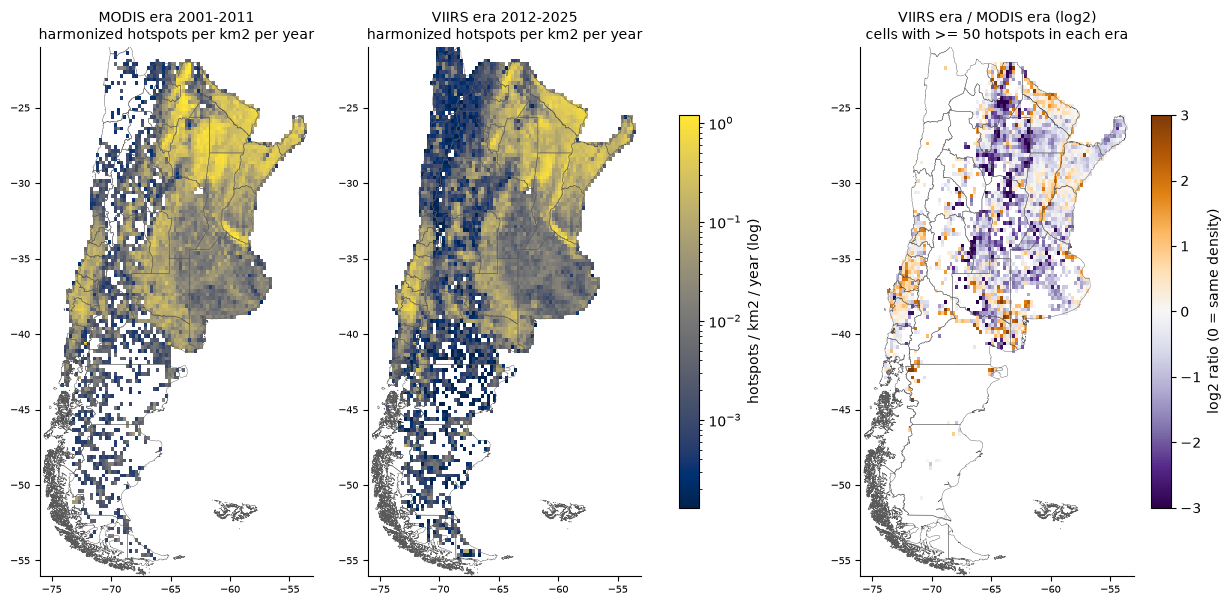

Cells with any harmonized hotspot: 5144 | with >= 50 in both eras: 2484
log2 ratio, cells with >= 50 in both eras: median -0.39 (ratio 0.76), IQR -1.15 to 0.29; share within a factor 2: 61%


In [3]:
ERA = {'MODIS era 2001-2011': (2001, 2011), 'VIIRS era 2012-2025': (2012, 2025)}
dens = q("""SELECT cell_lat, cell_lon,
    sum(hotspots_harmonized) FILTER (WHERE y BETWEEN 2001 AND 2011) h_modis,
    sum(hotspots_harmonized) FILTER (WHERE y BETWEEN 2012 AND 2025) h_viirs
  FROM c GROUP BY ALL""").fillna(0)
dens['area_km2'] = area_km2(dens.cell_lat)
dens['d_modis'] = dens.h_modis / 11 / dens.area_km2
dens['d_viirs'] = dens.h_viirs / 14 / dens.area_km2
both = (dens.h_modis >= 50) & (dens.h_viirs >= 50)
with np.errstate(divide='ignore', invalid='ignore'):
    dens['log2_ratio'] = np.where(both, np.log2(dens.d_viirs / dens.d_modis.where(dens.d_modis > 0)), np.nan)

fig, axs = plt.subplots(1, 3, figsize=(15, 8.5))
pos = dens[['d_modis', 'd_viirs']].stack(); pos = pos[pos > 0]
norm = LogNorm(vmin=pos.quantile(.02), vmax=pos.quantile(.999))
for ax, col, name in zip(axs[:2], ['d_modis', 'd_viirs'], ERA):
    im = draw_map(ax, dens[dens[col] > 0], col, f'{name}\nharmonized hotspots per km2 per year', cmap='cividis', norm=norm)
plt.colorbar(im, ax=axs[:2], shrink=.6, label='hotspots / km2 / year (log)')
im = draw_map(axs[2], dens[both], 'log2_ratio', 'VIIRS era / MODIS era (log2)\ncells with >= 50 hotspots in each era', cmap='PuOr_r', norm=TwoSlopeNorm(0, -3, 3))
plt.colorbar(im, ax=axs[2], shrink=.6, label='log2 ratio (0 = same density)')
plt.show()

print('Cells with any harmonized hotspot:', len(dens), '| with >= 50 in both eras:', int(both.sum()))
r = dens.loc[both, 'log2_ratio']
print('log2 ratio, cells with >= 50 in both eras: median %.2f (ratio %.2f), IQR %.2f to %.2f; share within a factor 2: %.0f%%'
      % (r.median(), 2 ** r.median(), r.quantile(.25), r.quantile(.75), 100 * (r.abs() <= 1).mean()))

In [4]:
# Does the ratio jump at region borders? Compare neighbouring cells (east-west and north-south pairs)
# in the same region against neighbouring cells in different regions. A harmonization artefact would
# make the jump across a border much larger than inside a region.
rr = dens.loc[both, ['cell_lat', 'cell_lon', 'log2_ratio']].merge(reg, on=['cell_lat', 'cell_lon'])
pairs = []
for dlat, dlon in [(0, .25), (.25, 0)]:
    nb = rr.assign(cell_lat=rr.cell_lat - dlat, cell_lon=rr.cell_lon - dlon)
    m = rr.merge(nb, on=['cell_lat', 'cell_lon'], suffixes=('', '_n'))
    pairs.append(m)
pairs = pd.concat(pairs, ignore_index=True)
pairs['same_region'] = pairs.admin1 == pairs.admin1_n
pairs['jump'] = (pairs.log2_ratio - pairs.log2_ratio_n).abs()
jumps = pairs.groupby('same_region').jump.describe(percentiles=[.5, .9])[['count', 'mean', '50%', '90%']]
display(jumps.round(2))

# Ratio per region (sum of hotspots, so big cells weigh more), regions with >= 2,000 hotspots in each era
byreg = dens.merge(reg, on=['cell_lat', 'cell_lon']).groupby(['country', 'admin1'])[['h_modis', 'h_viirs']].sum()
byreg = byreg[(byreg.h_modis >= 2000) & (byreg.h_viirs >= 2000)]
byreg['viirs_over_modis_per_year'] = (byreg.h_viirs / 14) / (byreg.h_modis / 11)
display(byreg.sort_values('viirs_over_modis_per_year').round(2))

,count,mean,50%,90%
same_region,,,,
False,376.0,0.90,0.69,1.92
True,3759.0,0.87,0.63,1.94


h_modis    h_viirs  viirs_over_modis_per_year
country   admin1                                                                                   
Argentina Santiago del Estero                       443175.11  237992.21                       0.42
          Catamarca                                  30881.17   16730.47                       0.43
          San Luis                                   95913.79   53066.49                       0.43
          Salta                                     365447.11  215639.14                       0.46
Chile     Región de Los Ríos                          9331.06    5656.54                       0.48
Argentina La Pampa                                  117585.21   86989.60                       0.58
          Córdoba                                    93890.30   70050.65                       0.59
          Misiones                                   98879.26   74036.25                       0.59
          Tucumán                                    73930.56   60402.00                       0.64
          Chaco                                     299235.28  251345.10                       0.66
          Jujuy                                      31612.84   27310.74                       0.68
          Mendoza                                    51684.93   45088.49                       0.69
          Buenos Aires                               82456.65   78445.63                       0.75
          Entre Ríos                                132717.98  126653.86                       0.75
          San Juan                                   18418.74   18387.66                       0.78
          Corrientes                                241174.92  268996.28                       0.88
Chile     Región de Valparaíso                        8824.82   10708.08                       0.95
Argentina Santa Fe                                  305156.14  378309.85                       0.97
Chile     Región de Los Lagos                         6605.82    8322.61                       0.99
          Región del Libertador Bernardo O'Higgins   14659.19   18588.60                       1.00
Argentina La Rioja                                   16235.07   21805.40                       1.06
          Río Negro                                  42647.67   60486.16                       1.11
          Santa Cruz                                  3723.13    5417.33                       1.14
          Formosa                                   265365.07  392648.67                       1.16
Chile     Región de La Araucanía                     47014.95   76482.09                       1.28
          Región del Bío-Bío                         33682.28   60795.69                       1.42
          Región del Maule                           28770.93   55834.82                       1.52
          Región de Ñuble                            20048.87   38909.49                       1.52
          Región Metropolitana de Santiago            6064.76   11831.86                       1.53
Argentina Neuquén                                    14982.05   29683.95                       1.56
          Chubut                                      5617.03   17617.29                       2.46

**Reading.**

- **Where it burns.** In both eras the densest band is northern Argentina between 25°S and 35°S: the 30-35°S band holds 52% of the 2012-2025 hotspots, with 0.13 hotspots per km² per year,
  against 0.04 to 0.05 in the 35-45°S bands and under 0.01 south of 45°S. The densest cells (about 0.8 to 1.1 hotspots per km² per year) are on the Paraná river: the islands of Entre Ríos
  and Santa Fe, then Formosa and the Salta lowlands. In Chile the dense band is the centre-south (Maule to La Araucanía). The per-km² correction matters most in the far south, where cells are
  about 40% smaller than in the north, but there the counts are so small that the ranking does not change.
- **Ratio map (check of the harmonization).** On the 2,484 cells with at least 50 hotspots in each era, the median VIIRS-era / MODIS-era ratio is 0.76 (log2 -0.39), and 61% of the cells are within
  a factor 2. **No region outline:** the jump of the log2 ratio between neighbouring cells is about the same inside a region (median 0.63) and across a region border (0.69), so the region and month
  factors of block 3 do not draw their borders on the map.
- **What the ratio shows instead.** Less fire in the VIIRS era in the dry Chaco (Santiago del Estero 0.42, Salta 0.46, San Luis and Catamarca 0.43), more in central-south Chile (Maule, Ñuble 1.52,
  Biobío 1.42: the 2017 and 2023 seasons), Neuquén (1.56) and Chubut (2.46), and sharp orange lines along the Paraná delta and the Corrientes wetlands (the 2020 and 2022 fires).
  These are known changes in fire activity, which is what the harmonization should show. The overall level (0.76) is not proof of a decline: the MODIS-era numbers are estimates, and block 4 makes
  no trend claim.

In [5]:
# Top cells by density in the VIIRS era, and the north-south gradient of the area correction.
top = dens.merge(reg, on=['cell_lat', 'cell_lon'], how='left').sort_values('d_viirs', ascending=False).head(10)
display(top[['cell_lat', 'cell_lon', 'country', 'admin1', 'h_viirs', 'area_km2', 'd_viirs', 'd_modis']].round(3).reset_index(drop=True))
band = dens.assign(lat_band=(np.floor(dens.cell_lat / 5) * 5).astype(int)).groupby('lat_band').agg(
    cells=('h_viirs', 'size'), hotspots_2012_2025=('h_viirs', 'sum'), area_km2=('area_km2', 'sum'))
band['per_km2_year'] = band.hotspots_2012_2025 / 14 / band.area_km2
band['share_of_hotspots_pct'] = 100 * band.hotspots_2012_2025 / band.hotspots_2012_2025.sum()
display(band.sort_index(ascending=False).round(4))

,cell_lat,cell_lon,country,admin1,h_viirs,area_km2,d_viirs,d_modis
0,-33.75,-59.50,Argentina,Entre Ríos,10356.000,644.918,1.147,1.305
1,-29.50,-61.00,Argentina,Santa Fe,8974.670,674.929,0.950,0.714
2,-29.00,-60.75,Argentina,Santa Fe,8980.375,678.218,0.946,0.860
3,-29.75,-61.50,Argentina,Santa Fe,8332.796,673.265,0.884,0.846
4,-25.25,-58.25,Argentina,Formosa,8563.819,701.228,0.872,0.921
5,-23.00,-64.25,Argentina,Salta,8351.000,713.598,0.836,0.287
6,-33.25,-60.25,Argentina,Entre Ríos,7455.000,648.636,0.821,0.935
7,-23.25,-64.25,Argentina,Salta,8032.000,712.277,0.805,0.733
8,-29.50,-61.25,Argentina,Santa Fe,7515.107,674.929,0.795,0.616
9,-28.75,-60.75,Argentina,Santa Fe,7556.767,679.844,0.794,0.954


,cells,hotspots_2012_2025,area_km2,per_km2_year,share_of_hotspots_pct
lat_band,,,,,
-20,55,1.732350e+03,40285.0635,0.0031,0.0609
-25,521,3.695400e+05,370416.5449,0.0713,12.9880
-30,1188,1.483390e+06,815506.2523,0.1299,52.1359
-35,1101,4.693435e+05,718945.6645,0.0466,16.4958
-40,1212,4.585650e+05,745805.5655,0.0439,16.1169
-45,595,5.080886e+04,342057.6345,0.0106,1.7858
-50,316,7.308254e+03,165420.0779,0.0032,0.2569
-55,156,4.547423e+03,73877.3964,0.0044,0.1598


## 5.2 Fire regimes

For each cell with at least 100 harmonized hotspots in 2012-2025: the share of its hotspots in each calendar month (12 numbers that add up to 1).
The profiles are clustered with k-means (k = 4, 5, 6; 20 starts, fixed seed). The choice of k uses the silhouette score (how well separated the groups are) and whether each group is
interpretable on the map. For each group: number of cells, hotspots, peak month of the mean profile, and the season length (the shortest run of consecutive months, circular, holding 80%
of the hotspots, same definition as block 4.2).

Months are treated as 12 separate dimensions, so December and January are as far apart as June and January. With shares that move gradually this matters little; it is stated as a limit.

In [6]:
prof = q("""SELECT cell_lat, cell_lon, mo, sum(hotspots_harmonized) h FROM c WHERE y BETWEEN 2012 AND 2025 GROUP BY ALL""")
P = prof.pivot_table(index=['cell_lat', 'cell_lon'], columns='mo', values='h', aggfunc='sum').reindex(columns=range(1, 13)).fillna(0)
tot12 = P.sum(axis=1)
P = P[tot12 >= 100]; tot12 = tot12[tot12 >= 100]
S = P.div(P.sum(axis=1), axis=0)
print(len(S), 'cells with >= 100 harmonized hotspots in 2012-2025 (of', len(dens), 'cells with any);',
      'they hold %.1f%% of the 2012-2025 hotspots' % (100 * tot12.sum() / dens.h_viirs.sum()))

def season_len(share):
    share = np.asarray(share)
    return next(L for L in range(1, 13) if any(share[[(s + k) % 12 for k in range(L)]].sum() >= .8 for s in range(12)))

fits, scores = {}, []
for k in [4, 5, 6]:
    km = KMeans(n_clusters=k, n_init=20, random_state=0).fit(S.values)
    fits[k] = km
    sil = silhouette_score(S.values, km.labels_, sample_size=min(len(S), 5000), random_state=0)
    sizes = np.bincount(km.labels_)
    scores.append(dict(k=k, silhouette=round(sil, 3), inertia=round(km.inertia_, 1), smallest_group_cells=int(sizes.min()), largest_group_cells=int(sizes.max())))
display(pd.DataFrame(scores))

2282 cells with >= 100 harmonized hotspots in 2012-2025 (of 5144 cells with any); they hold 97.6% of the 2012-2025 hotspots


,k,silhouette,inertia,smallest_group_cells,largest_group_cells
0,4,0.370,194.2,132,1610
1,5,0.264,170.4,105,1245
2,6,0.261,149.7,96,1041


In [7]:
def describe(k):
    lab = pd.Series(fits[k].labels_, index=S.index)
    rows = []
    for g in range(k):
        idx = lab[lab == g].index
        w = P.loc[idx].sum() / P.loc[idx].sum().sum()          # profile weighted by hotspots
        cells_ = reg.set_index(['cell_lat', 'cell_lon']).reindex(idx)
        lat = np.array([i[0] for i in idx]); lon = np.array([i[1] for i in idx])
        rows.append(dict(group=g, cells=len(idx), hotspots_2012_2025=int(P.loc[idx].values.sum()),
                         peak_month=MN[int(np.argmax(w.values))], peak_share_pct=round(100 * w.max(), 1), months_for_80pct=season_len(w.values),
                         lat_median=round(np.median(lat), 1), lon_median=round(np.median(lon), 1),
                         main_regions=', '.join(cells_.admin1.value_counts().head(3).index), **{MN[i]: round(w.iloc[i], 3) for i in range(12)}))
    return pd.DataFrame(rows).sort_values('lat_median', ascending=False).reset_index(drop=True), lab

for k in [4, 5, 6]:
    d, _ = describe(k)
    print(f'k = {k}'); display(d.drop(columns=MN))

k = 4


,group,cells,hotspots_2012_2025,peak_month,peak_share_pct,months_for_80pct,lat_median,lon_median,main_regions
0,0,1610,2200000,Aug,23.6,7,-29.2,-62.2,"Santa Fe, Santiago del Estero, Buenos Aires"
1,1,186,153986,Jan,59.7,5,-37.0,-66.5,"La Pampa, Mendoza, Río Negro"
2,2,354,342087,Feb,29.5,6,-37.8,-71.2,"Región de La Araucanía, Región del Bío-Bío, Co..."
3,3,132,80785,Dec,51.8,4,-38.5,-65.6,"Río Negro, La Pampa, Buenos Aires"


k = 5


,group,cells,hotspots_2012_2025,peak_month,peak_share_pct,months_for_80pct,lat_median,lon_median,main_regions
0,0,1245,1742978,Aug,25.5,6,-28.8,-62.5,"Santiago del Estero, Santa Fe, Salta"
1,4,659,717141,Mar,13.1,9,-34.5,-64.8,"Buenos Aires, Entre Ríos, Corrientes"
2,1,161,131159,Jan,63.9,3,-37.0,-66.8,"La Pampa, Mendoza, Río Negro"
3,3,105,116849,Feb,56.6,4,-38.2,-71.0,"Río Negro, Chubut, Región del Bío-Bío"
4,2,112,68731,Dec,56.5,3,-39.0,-65.5,"Río Negro, La Pampa, Buenos Aires"


k = 6


,group,cells,hotspots_2012_2025,peak_month,peak_share_pct,months_for_80pct,lat_median,lon_median,main_regions
0,0,394,517624,Sep,33.3,4,-26.8,-64.2,"Salta, Santiago del Estero, Córdoba"
1,2,1041,1538340,Aug,27.4,8,-29.5,-61.2,"Santa Fe, Corrientes, Chaco"
2,1,475,423986,Mar,16.8,8,-36.2,-68.5,"Buenos Aires, Región de La Araucanía, Región d..."
3,3,162,131002,Jan,63.9,3,-37.0,-66.8,"La Pampa, Mendoza, Río Negro"
4,4,96,95799,Feb,61.2,4,-38.5,-70.8,"Río Negro, Chubut, Neuquén"
5,5,114,70107,Dec,56.0,3,-39.0,-65.4,"Río Negro, La Pampa, Buenos Aires"


,regime,name,cells,hotspots_2012_2025,peak_month,peak_share_pct,months_for_80pct,lat_median,lon_median,main_regions
0,0,Winter-spring,1610,2200000,Aug,23.6,7,-29.2,-62.2,"Santa Fe, Santiago del Estero, Buenos Aires"
1,1,January pulse,186,153986,Jan,59.7,5,-37.0,-66.5,"La Pampa, Mendoza, Río Negro"
2,2,Late summer,354,342087,Feb,29.5,6,-37.8,-71.2,"Región de La Araucanía, Región del Bío-Bío, Co..."
3,3,December pulse,132,80785,Dec,51.8,4,-38.5,-65.6,"Río Negro, La Pampa, Buenos Aires"


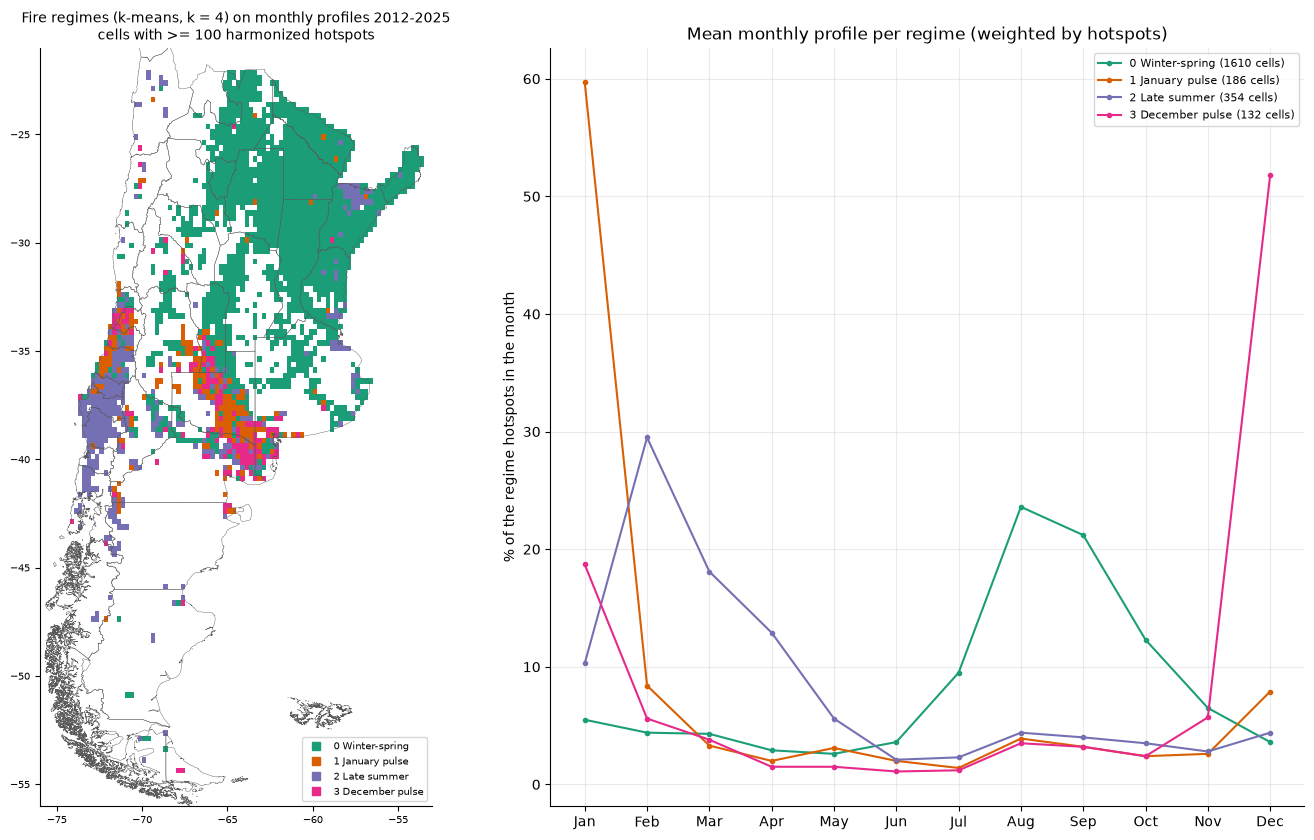

In [8]:
K = 4   # chosen after reading the three solutions above (see the reading below and the findings file)
desc, lab = describe(K)
# Stable numbering: regimes ordered north to south by median latitude; names given after reading the profiles.
order = {g: i for i, g in enumerate(desc.group)}
desc['regime'] = desc.group.map(order); lab = lab.map(order)
NAMES = {0: 'Winter-spring', 1: 'January pulse', 2: 'Late summer', 3: 'December pulse'}
desc['name'] = desc.regime.map(NAMES)
display(desc[['regime', 'name', 'cells', 'hotspots_2012_2025', 'peak_month', 'peak_share_pct', 'months_for_80pct', 'lat_median', 'lon_median', 'main_regions']])

COL = ['#1b9e77', '#d95f02', '#7570b3', '#e7298a', '#66a61e', '#e6ab02'][:K]
cmap = ListedColormap(COL); bnorm = BoundaryNorm(np.arange(-.5, K), K)
reg_df = lab.rename('regime').reset_index()
fig, axs = plt.subplots(1, 2, figsize=(14, 8.5), gridspec_kw={'width_ratios': [1, 1.25]})
draw_map(axs[0], reg_df, 'regime', f'Fire regimes (k-means, k = {K}) on monthly profiles 2012-2025\ncells with >= 100 harmonized hotspots', cmap=cmap, norm=bnorm)
for i in range(K): axs[0].plot([], [], 's', color=COL[i], label=f'{i} {NAMES[i]}')
axs[0].legend(fontsize=7, loc='lower right')
for i, r in desc.iterrows():
    axs[1].plot(range(1, 13), r[MN].values.astype(float) * 100, '-o', color=COL[r.regime], ms=3, label=f'{r.regime} {r["name"]} ({r.cells} cells)')
axs[1].set(xticks=range(1, 13), xticklabels=MN, ylabel='% of the regime hotspots in the month', title='Mean monthly profile per regime (weighted by hotspots)')
axs[1].legend(fontsize=8); axs[1].grid(alpha=.25)
plt.tight_layout(); plt.show()

**Reading: why k = 4.**

- **Silhouette** is highest for k = 4 (0.37 against 0.26 for k = 5 and 6). With k = 5 the extra group is a flat profile (peak March with only 13%, 9 months for 80%) that puts central-south Chile together
  with Buenos Aires and Entre Ríos: it separates "peaked" from "flat" cells, not seasons. k = 6 splits the northern group into August (humid Chaco, Paraná) and September (dry Chaco, Córdoba):
  a real difference of one month that block 4.2 already shows per region.
- **The four regimes** (numbered north to south by median latitude):
  - **0 Winter-spring** (1,610 cells, 2.2 million hotspots, 79% of the classified total): peak in August (24%), then September; 7 months hold 80%. Northern and central Argentina: Chaco,
    Santiago del Estero, Santa Fe, Formosa, Salta, Corrientes, Entre Ríos, northern Buenos Aires.
  - **1 January pulse** (186 cells): 60% of the hotspots in January, 5 months for 80%. La Pampa, southern Mendoza, Río Negro (the Monte and caldenal shrublands), plus a few cells in central Chile.
  - **2 Late summer** (354 cells): peak in February (30%), long tail to April; 6 months for 80%. Central-south Chile (Maule to Los Lagos), the Andes of Neuquén and Chubut, and the north-east of
    Corrientes and Misiones (the January-February 2022 fires).
  - **3 December pulse** (132 cells): 52% in December, 4 months for 80%. Southern La Pampa, Río Negro and southern Buenos Aires, and Santiago / Valparaíso in Chile.
- The names describe timing, not vegetation: the regimes come only from monthly profiles, not from land cover.

### Regions that contain two or more regimes

Each cell takes the region holding most of its hotspots. A region "mixes" regimes when a second regime holds at least 10% of its classified cells **and** at least 3 cells
(below that, a stray cell on a border is enough). Hotspot shares are also given: a minority regime can hold few cells but many hotspots, or the reverse.

In [9]:
rc = reg_df.merge(reg, on=['cell_lat', 'cell_lon'], how='left').merge(tot12.rename('h').reset_index(), on=['cell_lat', 'cell_lon'])
rc['name'] = rc.regime.map(NAMES)
ct = rc.groupby(['country', 'admin1', 'name']).agg(cells=('h', 'size'), hotspots=('h', 'sum')).reset_index()
ct['cell_share'] = ct.cells / ct.groupby('admin1').cells.transform('sum')
ct['hotspot_share'] = ct.hotspots / ct.groupby('admin1').hotspots.transform('sum')
sig = ct[(ct.cell_share >= .10) & (ct.cells >= 3)]
nreg = sig.groupby(['country', 'admin1']).name.nunique()
mixed = nreg[nreg >= 2].index
print(f'{len(nreg)} regions with classified cells; {len(mixed)} contain two or more regimes')
tab = (ct.set_index(['country', 'admin1']).loc[mixed].reset_index()
       .assign(cells_pct=lambda d: (100 * d.cell_share).round(0), hotspots_pct=lambda d: (100 * d.hotspot_share).round(0))
       .pivot_table(index=['country', 'admin1'], columns='name', values='cells_pct', fill_value=0))
display(tab)
hs = (ct.set_index(['country', 'admin1']).loc[mixed].reset_index()
      .pivot_table(index=['country', 'admin1'], columns='name', values='hotspot_share', fill_value=0) * 100).round(0)
print('Share of the region hotspots (%) per regime:'); display(hs)
single = nreg[nreg == 1]
print('Regions with one regime:', ', '.join(f'{a} ({c[:3]})' for c, a in single.index))

35 regions with classified cells; 14 contain two or more regimes


name                                                December pulse  January pulse  Late summer  Winter-spring
country   admin1                                                                                             
Argentina Buenos Aires                                         9.0            7.0         12.0           72.0
          Chubut                                              12.0           15.0         73.0            0.0
          Corrientes                                           1.0            1.0         20.0           79.0
          La Pampa                                            18.0           43.0         13.0           27.0
          Mendoza                                              8.0           29.0          5.0           58.0
          Neuquén                                              7.0           13.0         44.0           35.0
          Río Negro                                           34.0           17.0         25.0           24.0
          San Juan                                            16.0            3.0          0.0           81.0
          Santa Cruz                                          10.0           10.0         40.0           40.0
Chile     Región Metropolitana de Santiago                    43.0           50.0          7.0            0.0
          Región de Atacama                                   18.0           18.0         27.0           36.0
          Región de Valparaíso                                24.0           24.0         24.0           29.0
          Región del Libertador Bernardo O'Higgins            15.0           30.0         40.0           15.0
          Región del Maule                                     2.0           31.0         53.0           13.0

Share of the region hotspots (%) per regime:


name                                                December pulse  January pulse  Late summer  Winter-spring
country   admin1                                                                                             
Argentina Buenos Aires                                        12.0            8.0         14.0           66.0
          Chubut                                               7.0           11.0         82.0            0.0
          Corrientes                                           1.0            1.0         24.0           74.0
          La Pampa                                            19.0           58.0          9.0           14.0
          Mendoza                                              6.0           21.0          3.0           70.0
          Neuquén                                              9.0            7.0         45.0           38.0
          Río Negro                                           42.0           16.0         21.0           22.0
          San Juan                                            18.0            1.0          0.0           81.0
          Santa Cruz                                           6.0            6.0         44.0           44.0
Chile     Región Metropolitana de Santiago                    51.0           43.0          6.0            0.0
          Región de Atacama                                   18.0           27.0         22.0           34.0
          Región de Valparaíso                                27.0           32.0         25.0           15.0
          Región del Libertador Bernardo O'Higgins            18.0           31.0         37.0           14.0
          Región del Maule                                     2.0           53.0         38.0            7.0

Regions with one regime: Catamarca (Arg), Chaco (Arg), Córdoba (Arg), Entre Ríos (Arg), Formosa (Arg), Jujuy (Arg), La Rioja (Arg), Misiones (Arg), Salta (Arg), San Luis (Arg), Santa Fe (Arg), Santiago del Estero (Arg), Tucumán (Arg), Región de Antofagasta (Chi), Región de Aysén del Gral.Ibañez del Campo (Chi), Región de Coquimbo (Chi), Región de La Araucanía (Chi), Región de Los Lagos (Chi), Región de Los Ríos (Chi), Región de Ñuble (Chi), Región del Bío-Bío (Chi)


In [10]:
# Stability of the regimes: do the regimes of the VIIRS era (2012-2025) come back if the clustering is
# fitted on the two halves of the period separately? Agreement measured with the adjusted Rand index.
from sklearn.metrics import adjusted_rand_score
halves = {}
for name, (a, b) in {'2012-2018': (2012, 2018), '2019-2025': (2019, 2025)}.items():
    ph = q(f"""SELECT cell_lat, cell_lon, mo, sum(hotspots_harmonized) h FROM c WHERE y BETWEEN {a} AND {b} GROUP BY ALL""")
    Ph = ph.pivot_table(index=['cell_lat', 'cell_lon'], columns='mo', values='h', aggfunc='sum').reindex(index=S.index, columns=range(1, 13)).fillna(0)
    ok = Ph.sum(axis=1) >= 50
    halves[name] = (ok, KMeans(n_clusters=K, n_init=20, random_state=0).fit(Ph[ok].div(Ph[ok].sum(axis=1), axis=0).values).labels_, Ph)
ok = halves['2012-2018'][0] & halves['2019-2025'][0]
l1 = pd.Series(halves['2012-2018'][1], index=S.index[halves['2012-2018'][0]]).reindex(S.index[ok])
l2 = pd.Series(halves['2019-2025'][1], index=S.index[halves['2019-2025'][0]]).reindex(S.index[ok])
print(f'Cells with >= 50 hotspots in both halves: {ok.sum()}')
print('Adjusted Rand index, 2012-2018 vs 2019-2025: %.2f' % adjusted_rand_score(l1, l2))
print('Adjusted Rand index, full period vs 2012-2018: %.2f, vs 2019-2025: %.2f' % (adjusted_rand_score(lab[ok], l1), adjusted_rand_score(lab[ok], l2)))

Cells with >= 50 hotspots in both halves: 1894
Adjusted Rand index, 2012-2018 vs 2019-2025: 0.27
Adjusted Rand index, full period vs 2012-2018: 0.68, vs 2019-2025: 0.30


In [11]:
# How much of each regime comes from its single largest season (July-June, labelled by the year it starts, as season_year)?
# A regime shaped by one season is an event, not a recurring calendar.
lab_df = lab.rename('regime').reset_index()
con.register('lab_df', lab_df)
dom = q("""WITH s AS (SELECT l.regime, CASE WHEN mo >= 7 THEN y ELSE y - 1 END AS season, sum(hotspots_harmonized) h
              FROM c JOIN lab_df l USING (cell_lat, cell_lon) WHERE y BETWEEN 2012 AND 2025 GROUP BY ALL)
         SELECT regime, season AS top_season, h, h / sum(h) OVER (PARTITION BY regime) AS share FROM s
         QUALIFY row_number() OVER (PARTITION BY regime ORDER BY h DESC) = 1 ORDER BY regime""")
dom['name'] = dom.regime.map(NAMES); dom['share_pct'] = (100 * dom.share).round(1)
display(dom[['regime', 'name', 'top_season', 'share_pct']])

,regime,name,top_season,share_pct
0,0,Winter-spring,2020,14.1
1,1,January pulse,2016,33.4
2,2,Late summer,2022,15.9
3,3,December pulse,2016,37.2


In [12]:
# Output table for the app and the risk model.
cr = S.copy(); cr['peak_month'] = (S.values.argmax(axis=1) + 1)
cr = cr[['peak_month']].reset_index().merge(reg_df, on=['cell_lat', 'cell_lon'])
cr = cr.merge(dens[['cell_lat', 'cell_lon', 'd_viirs']].rename(columns={'d_viirs': 'hotspots_per_km2_year'}), on=['cell_lat', 'cell_lon'])
cr = cr[['cell_lat', 'cell_lon', 'regime', 'peak_month', 'hotspots_per_km2_year']].sort_values(['cell_lat', 'cell_lon']).reset_index(drop=True)
cr['regime'] = cr.regime.astype('int8'); cr['peak_month'] = cr.peak_month.astype('int8')
cr.to_parquet(OUT / 'cell_regimes.parquet', index=False)
pd.DataFrame({'regime': range(K), 'name': [NAMES[i] for i in range(K)]}).to_csv(OUT / 'regime_names.csv', index=False)
print(len(cr), 'cells saved to', (OUT / 'cell_regimes.parquet').relative_to(ROOT), '| regime names in', (OUT / 'regime_names.csv').relative_to(ROOT))
print('hotspots_per_km2_year: harmonized hotspots per km2 per year, 2012-2025. peak_month: 1-12, the cell own peak month.')
display(cr.head())

2282 cells saved to NASA_Data_Sources/processed/spatial/cell_regimes.parquet | regime names in NASA_Data_Sources/processed/spatial/regime_names.csv
hotspots_per_km2_year: harmonized hotspots per km2 per year, 2012-2025. peak_month: 1-12, the cell own peak month.


,cell_lat,cell_lon,regime,peak_month,hotspots_per_km2_year
0,-54.5,-68.00,3,12,0.112098
1,-54.5,-67.75,3,12,0.122865
2,-54.0,-70.00,2,2,0.029722
3,-53.5,-68.75,0,8,0.021024
4,-53.0,-70.25,2,2,0.016961


**Reading.**

- **Regions that mix regimes.** 14 of the 35 regions with classified cells contain two or more regimes (a second regime with at least 10% of the cells and 3 cells). In Argentina: Buenos Aires,
  Chubut, Corrientes, La Pampa, Mendoza, Neuquén, Río Negro, San Juan and Santa Cruz. In Chile: Metropolitana, Atacama, Valparaíso, O'Higgins and Maule.
  The strongest mixes: **La Pampa** (January pulse 58% of its hotspots, December pulse 19%, winter-spring 14%), **Río Negro** (December 42%, winter-spring 22%, late summer 21%), **Neuquén**
  (late summer 45%, winter-spring 38%), **Corrientes** (winter-spring 74%, late summer 24%) and **Maule** (January pulse 53%, late summer 38%).
- The other 21 regions hold one regime, including every large region of the north (Chaco, Santiago del Estero, Santa Fe, Formosa, Salta, Córdoba) and the Chilean south (Ñuble to Los Lagos).
  For them the administrative region is a good unit for the calendar. For the 14 mixed regions, a single regional profile averages two seasons and hides both.
- **Stability.** Fitted again on 2012-2018 and on 2019-2025 separately, the regimes agree only moderately (adjusted Rand index 0.27 between the halves; 0.68 and 0.30 against the full period).
  The large winter-spring regime is stable; the small summer regimes move.
- **Why they move.** The January and December pulses are shaped by one season: the 2016/17 season (July 2016 to June 2017) holds 33% and 37% of their hotspots, the La Pampa and Patagonia grass
  fires of December 2016 and January 2017. The winter-spring and late-summer regimes have no dominant season (their largest season holds 14% and 16%). So **two regimes are recurring calendars**
  (winter-spring, late summer) and **two are mostly the footprint of one extreme season** (January and December pulses, together "summer grassland pulses").

## 5.4 Sparse cells and the smallest usable cell size

For cells of 0.25°, 0.5° and 1° (larger cells are built from the 0.25° ones: `floor(cell_lat / size) * size`), over the complete months January 2001 to October 2026
(**310 months**; the task says 312, but November 2026 has 12 days and December 2026 has not happened, so counting them as zero months would inflate the zeros):

- **zero share**: the share of the 310 months with no harmonized hotspot in the cell. Only cells with at least one hotspot in the record count.
- **reliable**: the cell's peak month (calendar month with most hotspots in 2001-2025) has a **historical median of at least 10** harmonized hotspots over the 25 complete years 2001-2025.
  This is the reliability threshold of block 4: below it the calendar should show the count and no anomaly colour.

In [13]:
mon = q("""SELECT cell_lat, cell_lon, y, mo, sum(hotspots_harmonized) h FROM c
          WHERE burn_date <= DATE '2026-10-31' GROUP BY ALL""")
N_MONTHS = (2026 - 2001) * 12 + 10
mon = mon[mon.y >= 2001]
res, per_size = [], {}
for size in [0.25, 0.5, 1.0]:
    m = mon.assign(gl=np.floor(mon.cell_lat / size) * size, gx=np.floor(mon.cell_lon / size) * size).groupby(['gl', 'gx', 'y', 'mo'], as_index=False).h.sum()
    nz = m[m.h > 0].groupby(['gl', 'gx']).size()
    zero_share = 1 - nz / N_MONTHS
    full = m[m.y <= 2025]
    clim = full.groupby(['gl', 'gx', 'mo']).h.sum().reset_index()
    peak = clim.loc[clim.groupby(['gl', 'gx']).h.idxmax(), ['gl', 'gx', 'mo']]
    # median over the 25 years of the peak month, zeros included
    pm = full.merge(peak, on=['gl', 'gx', 'mo']).pivot_table(index=['gl', 'gx'], columns='y', values='h', aggfunc='sum').reindex(columns=range(2001, 2026)).fillna(0)
    med = pm.median(axis=1).reindex(zero_share.index).fillna(0)
    t = pd.DataFrame({'zero_share': zero_share, 'peak_median': med})
    per_size[size] = t
    tot_h = m.groupby(['gl', 'gx']).h.sum().reindex(t.index)
    res.append(dict(cell_deg=size, cells_with_fire=len(t),
                    median_zero_share_pct=round(100 * t.zero_share.median(), 1),
                    cells_zero_share_over_90pct=int((t.zero_share > .9).sum()),
                    reliable_cells=int((t.peak_median >= 10).sum()),
                    reliable_share_pct=round(100 * (t.peak_median >= 10).mean(), 1),
                    hotspots_in_reliable_cells_pct=round(100 * tot_h[t.peak_median >= 10].sum() / tot_h.sum(), 1),
                    typical_cell_km=round(size * KM * np.cos(np.radians(-35)), 0)))
summary = pd.DataFrame(res); display(summary)

,cell_deg,cells_with_fire,median_zero_share_pct,cells_zero_share_over_90pct,reliable_cells,reliable_share_pct,hotspots_in_reliable_cells_pct,typical_cell_km
0,0.25,5143,89.7,2532,759,14.8,66.5,23.0
1,0.50,1468,72.4,491,368,25.1,82.2,46.0
2,1.00,411,39.0,65,184,44.8,93.6,91.0


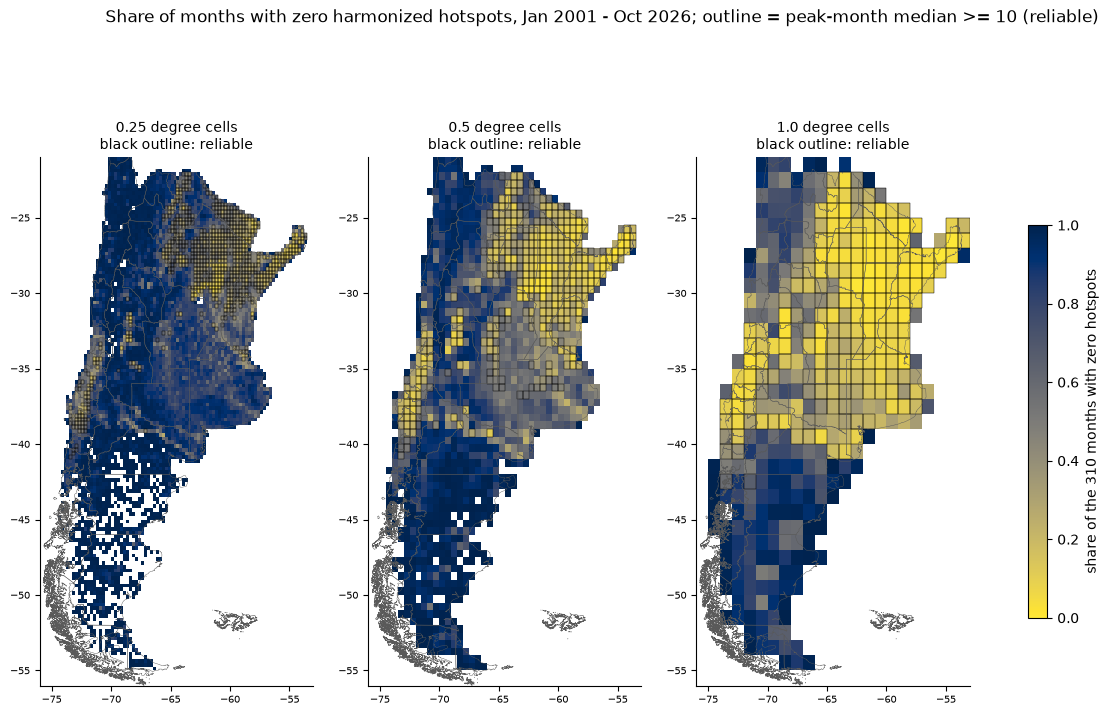

cells  reliable  median_zero_share
country   band                                    
Argentina -25     327        89               0.85
          -30    1029       519               0.54
          -35     970        82               0.82
          -40    1020         3               0.88
          -45     467         0               0.99
          -50     252         0               0.99
          -55      89         0               0.99
Chile     -20      55         0               0.96
          -25     194         0               0.98
          -30     159         0               0.98
          -35     131         8               0.86
          -40     192        53               0.64
          -45     127         5               0.97
          -50      64         0               0.99
          -55      67         0               0.99

In [14]:
fig, axs = plt.subplots(1, 3, figsize=(15, 8.5))
for ax, size in zip(axs, [0.25, 0.5, 1.0]):
    t = per_size[size].reset_index().rename(columns={'gl': 'cell_lat', 'gx': 'cell_lon'})
    t['rel'] = np.where(t.peak_median >= 10, 1.0, 0.0)
    im = draw_map(ax, t, 'zero_share', f'{size} degree cells\nblack outline: reliable', size=size, cmap='cividis_r', vmin=0, vmax=1)
    rel = t[t.rel == 1]
    ax.add_collection(PatchCollection([Rectangle((x, y), size, size) for x, y in zip(rel.cell_lon, rel.cell_lat)], facecolor='none', edgecolor='k', lw=.35))
plt.colorbar(im, ax=axs, shrink=.6, label='share of the 310 months with zero hotspots')
fig.suptitle('Share of months with zero harmonized hotspots, Jan 2001 - Oct 2026; outline = peak-month median >= 10 (reliable)')
plt.show()

# Where the 0.25 degree grid is reliable: per country and latitude band
t25 = per_size[0.25].reset_index().rename(columns={'gl': 'cell_lat', 'gx': 'cell_lon'}).merge(reg, on=['cell_lat', 'cell_lon'], how='left')
t25['band'] = (np.floor(t25.cell_lat / 5) * 5).astype(int)
display(t25.assign(reliable=t25.peak_median >= 10).groupby(['country', 'band']).agg(cells=('reliable', 'size'), reliable=('reliable', 'sum'),
        median_zero_share=('zero_share', 'median')).round(2).sort_index(level=[0, 1], ascending=[True, False]))

**Reading.**

- **0.25° cells are mostly empty.** Of the 5,143 cells with at least one hotspot, the median cell has no hotspot in 90% of the 310 months; 2,532 cells (49%) are empty in more than 90% of the months.
  Only 759 cells (15%) reach a peak-month median of 10 harmonized hotspots; they hold 67% of all hotspots. Most are in northern Argentina between 25°S and 35°S (608 cells), then the Argentine 35-40°S band (82)
  and the Chilean centre-south (61 cells between 35°S and 45°S).
- **0.5°** doubles the share of reliable cells: 368 of 1,468 (25%), holding 82% of the hotspots. **1°** reaches 184 of 411 (45%) and 94% of the hotspots, and its cells are about 90 km wide.
- South of 45°S and in northern Chile no cell size reaches the threshold: there the calendar can show counts, never an anomaly colour.
- **Smallest usable size: 0.5°** for an anomaly calendar on a single cell. The app can keep 0.25° for counts and maps, flag each cell with the reliable test above, and fall back to the region (or a
  user-drawn area that sums enough cells) when the flag is false.

## 5.3 Static sources (persistent points)

The static-source mask of block 1 (`static_mask_cells.parquet`): 0.005° cells (about 500 m) with detections on at least 60 days, in at least 9 calendar months and at least 5 years
of 2012-2025. These cells are removed by the quality filter, so they are not in the harmonized counts. Here: where they are and which have the most days with detections.

483 persistent 0.005 degree cells; 2 without a region in the harmonized cells


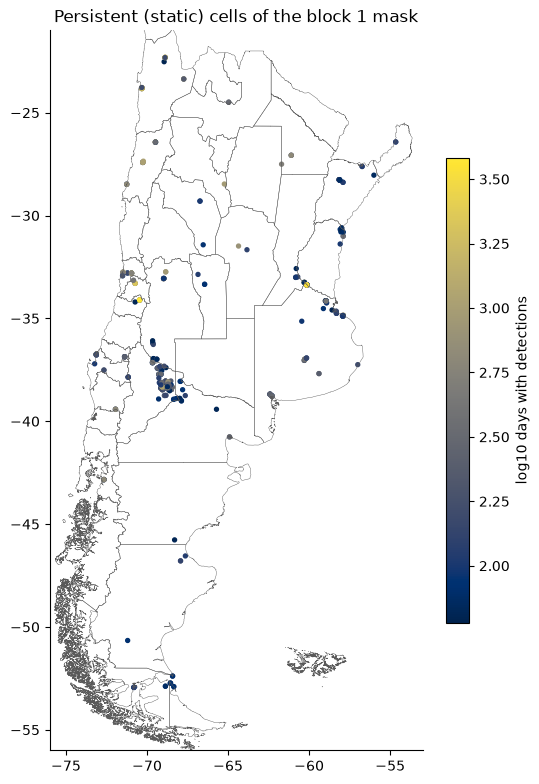

cells   days
country   admin1                             
Argentina Neuquén                  141  33962
          Buenos Aires              73  26553
          Entre Ríos                43  29410
          Mendoza                   26   7171
Chile     Región de Antofagasta     25  25181
          Región de Valparaíso      20  12443
          Región de Atacama         19  13670
          Región del Bío-Bío        17   5522
Argentina Corrientes                16   1976
          Santa Fe                  14  10170

Ten cells with most days of detections:


,lat,lon,ndays,country,admin1
0,-32.8025,-70.9525,3823,Chile,Región de Valparaíso
1,-34.1075,-70.4575,3808,Chile,Región del Libertador Bernardo O'Higgins
2,-23.8225,-70.3175,3520,Chile,Región de Antofagasta
3,-22.3175,-68.8825,3434,Chile,Región de Antofagasta
4,-33.3775,-60.1475,3415,Argentina,Entre Ríos
5,-33.2575,-60.2875,3167,Argentina,Santa Fe
6,-33.3675,-60.1625,3034,Argentina,Entre Ríos
7,-34.8575,-57.8925,2741,Argentina,Buenos Aires
8,-33.2575,-60.2825,2689,Argentina,Santa Fe
9,-26.4325,-69.4775,2656,Chile,Región de Atacama


In [15]:
if MASK.exists():
    mk = pd.read_parquet(MASK)
    mk['cell_lat'] = np.floor(mk.lat * 4) / 4; mk['cell_lon'] = np.floor(mk.lon * 4) / 4
    mk = mk.merge(reg, on=['cell_lat', 'cell_lon'], how='left')
    # Cells in no harmonized row (the filter removed all their hotspots) take the nearest region from the build table
    print(len(mk), 'persistent 0.005 degree cells;', mk.admin1.isna().sum(), 'without a region in the harmonized cells')
    fig, ax = plt.subplots(figsize=(5.5, 8.5))
    for r in RINGS: ax.plot(r[:, 0], r[:, 1], color='0.35', lw=.3)
    sc = ax.scatter(mk.lon, mk.lat, c=np.log10(mk.ndays), s=8, cmap='cividis'); plt.colorbar(sc, label='log10 days with detections', shrink=.6)
    ax.set_xlim(LON0, LON1); ax.set_ylim(LAT0, LAT1); ax.set_aspect(1 / np.cos(np.radians(38))); ax.set_title('Persistent (static) cells of the block 1 mask')
    plt.tight_layout(); plt.show()
    display(mk.groupby(['country', 'admin1'], dropna=False).agg(cells=('ndays', 'size'), days=('ndays', 'sum')).sort_values('cells', ascending=False).head(10))
    print('Ten cells with most days of detections:')
    display(mk.sort_values('ndays', ascending=False).head(10)[['lat', 'lon', 'ndays', 'country', 'admin1']].round(4).reset_index(drop=True))
else:
    print('static_mask_cells.parquet not found: run notebooks/01_quality.ipynb (pipeline step 6)')

**Reading.** The 483 persistent cells of the block 1 mask are industrial and urban heat, not vegetation fire. The ten cells with most days are in Chile (near the Chagres smelter in
Valparaíso, the El Teniente / Caletones smelter in O'Higgins, Calama and the Antofagasta coast, and one site in Atacama) and in Argentina along the Paraná at San Nicolás and Villa Constitución
(steel plants) and at Ensenada (refinery), each with 2,600 to 3,800 days of detections in 2012-2025. Neuquén has the most mask cells (141), probably oil and gas flares. These points are removed
by the quality filter, so they are not in the maps above. The site names are a reading of the coordinates, not checked against a list of facilities.